In [39]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from sklearn.linear_model import LinearRegression

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Libraries imported successfully!")
import os
# Load processed dataset
df = pd.read_csv(
    "../data/ipl_score_prediction.csv"
)

print("Dataset Shape:", df.shape)

display(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Libraries imported successfully!
Dataset Shape: (213, 6)


,Match_ID,Innings,Overs,Current_Runs,Wickets,Final_Runs
0,1,1,5,33,3,201
1,1,1,10,87,3,201
2,1,1,15,142,5,201
3,2,1,5,68,0,220
4,2,1,10,120,2,220



Missing Values:
Match_ID        0
Innings         0
Overs           0
Current_Runs    0
Wickets         0
Final_Runs      0
dtype: int64


STATISTICAL SUMMARY


,Match_ID,Innings,Overs,Current_Runs,Wickets,Final_Runs
count,213.000000,213.0,213.0000,213.000000,213.000000,213.000000
mean,38.028169,1.0,10.0000,95.117371,2.525822,195.774648
std,21.391216,0.0,4.0921,44.725160,1.755192,36.536954
min,1.000000,1.0,5.0000,11.000000,0.000000,75.000000
25%,20.000000,1.0,5.0000,58.000000,1.000000,163.000000
50%,38.000000,1.0,10.0000,93.000000,2.000000,201.000000
75%,57.000000,1.0,15.0000,127.000000,4.000000,222.000000
max,74.000000,1.0,15.0000,207.000000,8.000000,264.000000


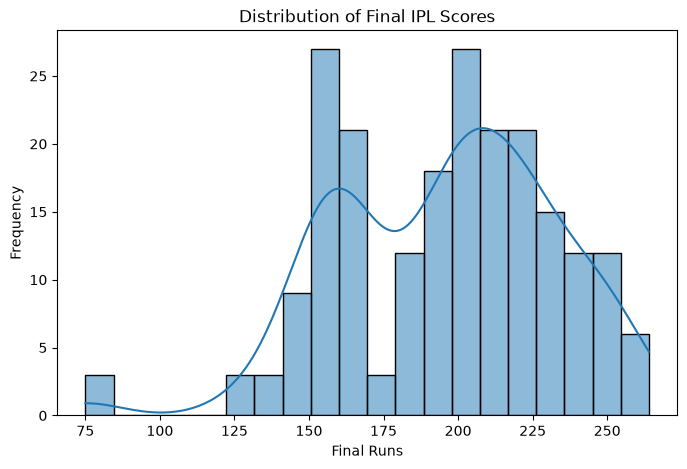

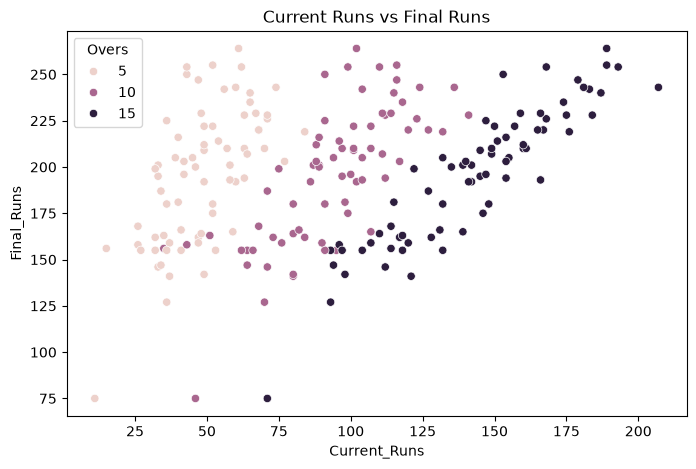

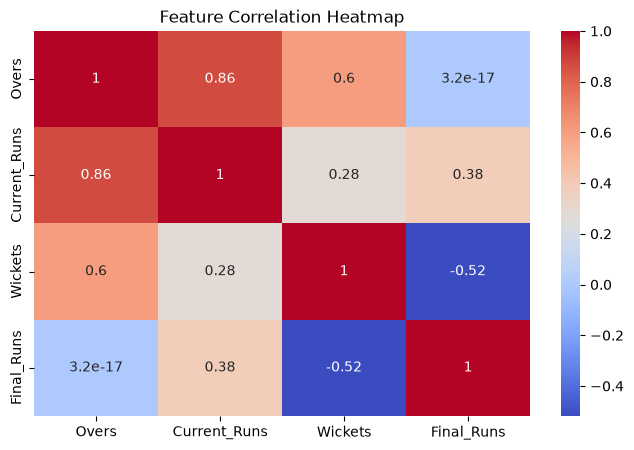

In [40]:
# Basic statistical information
print("STATISTICAL SUMMARY")
display(df.describe())

# Distribution of final scores
plt.figure(figsize=(8, 5))
sns.histplot(df["Final_Runs"], bins=20, kde=True)
plt.title("Distribution of Final IPL Scores")
plt.xlabel("Final Runs")
plt.ylabel("Frequency")
plt.show()

# Current runs vs final runs
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Current_Runs",
    y="Final_Runs",
    hue="Overs"
)
plt.title("Current Runs vs Final Runs")
plt.show()

# Correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    df[["Overs", "Current_Runs", "Wickets", "Final_Runs"]].corr(),
    annot=True,
    cmap="coolwarm"
)
plt.title("Feature Correlation Heatmap")
plt.show()

In [41]:
# Select input features
X = df[["Overs", "Current_Runs", "Wickets"]]

# Select target variable
Y = df["Final_Runs"]

# Match IDs will be used only for splitting
groups = df["Match_ID"]

print("Features shape:", X.shape)
print("Target shape:", Y.shape)

Features shape: (213, 3)
Target shape: (213,)


In [42]:
# Split data bY match ID
X_train, X_test, y_train, y_test = train_test_split(
    X, Y,
    test_size=0.20,
    random_state=42
)


In [43]:
# Create Linear Regression model

linear_model = LinearRegression()

# Train model
linear_model.fit(X_train, y_train)

print("Linear Regression Model Trained Successfully!")

Linear Regression Model Trained Successfully!


In [44]:
# Predict final scores

y_pred = linear_model.predict(X_test)

# Display actual vs predicted scores

results = pd.DataFrame({
    "Actual_Score": y_test.values,
    "Predicted_Score": y_pred.round(2)
})

display(results.head(15))

,Actual_Score,Predicted_Score
0,162,196.82
1,205,175.93
2,180,170.85
3,255,251.99
4,155,194.37
5,222,201.40
6,226,226.75
7,242,246.49
8,155,199.27
9,229,223.09


In [45]:
# Calculate evaluation metrics

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION PERFORMANCE")
print("--------------------------------")

print("MAE:", round(mae, 2))
print("MSE:", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

LINEAR REGRESSION PERFORMANCE
--------------------------------
MAE: 19.27
MSE: 643.82
RMSE: 25.37
R2 Score: 0.4764


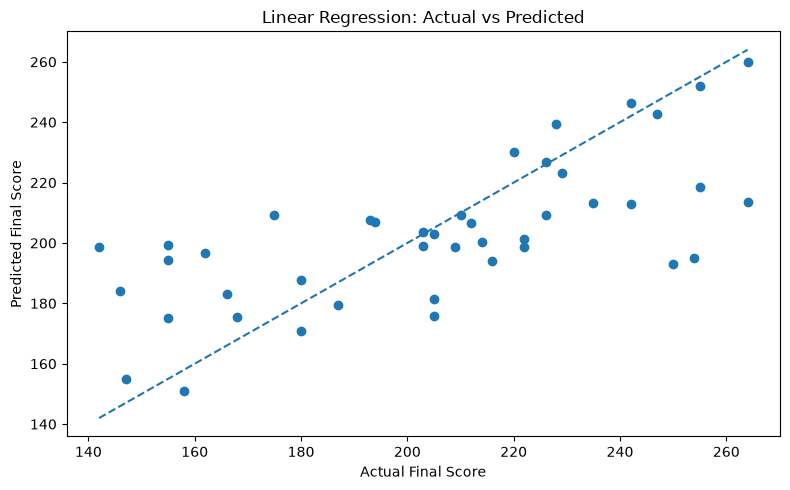

In [46]:
os.makedirs("../outputs", exist_ok=True)
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred)

plt.xlabel("Actual Final Score")
plt.ylabel("Predicted Final Score")

plt.title("Linear Regression: Actual vs Predicted")

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    linestyle="--"
)

plt.tight_layout()

# Save plot to output folder
plt.savefig('../outputs/predicted_vs_actual.png', dpi=300)
plt.show()